# 01 — Analysis: modelling fix, hypothesis test, rater agreement, fairness

**Status (2026-11-18):** all 3 raters (`fluent_c`, `instructor_a` = Maya, `instructor_b`) rated all 50
clips. **Agreement is below the pre-registered threshold** (ICC(2,k) = 0.20 < 0.6), so per the plan the
consensus result is exploratory and the per-rater results (§5b) plus agreement are the reported findings.
The model, features and test were fixed before the instructor ratings were seen and were **not** changed after.

Contents
1. Pre-registered analysis plan (fixed *before* the instructor ratings were seen)
2. Data status and rater agreement
3. Exploratory: single-feature correlations (diagnostic only — **not** used to choose features)
4. Why the original arms failed (overfitting at n = 50) and the fix
5. Ablation + paired hypothesis test on the 3-rater mean (exploratory under low agreement)
5b. Per-rater results (the pre-registered low-agreement fallback)
6. Fairness (proposal §7): objective skin-tone / lighting context, tracker-quality gap, stratified metrics
7. Boundary-sensitivity recap (Roadmap Gap 1)
8. Dress rehearsal on simulated raters (historical plumbing check)
9. Commands used to produce these results
10. Notes & limitations (for the paper)

## 1. Pre-registered analysis plan

Written down before any instructor rating exists, so nothing below can be tuned on the final ground truth.

| Item | Decision |
|---|---|
| Ground truth | Mean of **human** raters per clip (`vlm_*` rows excluded). Valid only if ICC(2,k) ≥ 0.6 (`asl-fluency agreement`). |
| Primary arm | `core_ridge_cv` — ridge with nested-LOO shrinkage over 3 a-priori features, one per construct in the RQ: rate (`letters_per_second`), smoothness (`log_dimless_jerk`), pauses (`pause_total_s`). |
| Baseline | `naive_speed_only` (letters/sec) — the hypothesis' comparator. |
| Primary test | Paired bootstrap Δ Spearman (primary − baseline) on signer-disjoint out-of-fold predictions; one-sided, α = .05; report Δ and 95% CI. |
| Reference | `mean_baseline` — MAE floor; any arm with worse MAE is not learning. |
| Secondary | `core_ordinal`, `kinematic_robust_ridge_cv`, legacy α=1 ridge / GBM — reported, never used to re-pick a winner after seeing held-out results. |
| Fairness | Marginal metrics + mean signed error per skin-tone (ITA proxy) and lighting stratum, on the primary arm. |
| Fallback (ICC < 0.6 or ratings late) | Report per-rater results (`evaluate --rater …`) and agreement as findings; no consensus claim. |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from asl_fluency.config import load_config, project_root, resolve_path
from asl_fluency.data.fluency_labels import consensus_scores, load_ratings
from asl_fluency.evaluation.ablation import (
    BASELINE_ARM,
    PRIMARY_ARM,
    marginal_stratified_metrics,
    run_ablation,
)
from asl_fluency.evaluation.agreement import agreement_report
from asl_fluency.features.pipeline import CORE_FEATURES, FEATURE_SETS
from asl_fluency.models.baseline import make_model

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

ROOT = project_root()
cfg = load_config()
RATINGS = resolve_path(cfg, "ratings_dir") / "ratings_intake.csv"
feats_all = pd.read_csv(resolve_path(cfg, "processed_dir") / "features.csv", dtype={"clip_id": str})
ratings = load_ratings(RATINGS, tuple(cfg["labels"]["rating_scale"]))  # blank rows dropped
print("project root:", ROOT)

project root: /Users/jasonkolodziej/Code/cs-5243-901-project/asl-fluency


## 2. Data status and rater agreement

In [2]:
sheet = pd.read_csv(RATINGS, dtype={"clip_id": str})
status = (sheet.assign(done=sheet["rating"].notna())
               .groupby("rater_id")["done"].agg(rated="sum", assigned="size"))
print(status, "\n")
y = consensus_scores(ratings)
feats = feats_all[feats_all["clip_id"].isin(y.index)].reset_index(drop=True)
print(f"rated clips with features: {len(feats)} | signers: {feats['signer_id'].nunique()} "
      f"| feature table: {len(feats_all):,} clips")
print("rating distribution:", y.value_counts().sort_index().to_dict(),
      f"| mean {y.mean():.2f}, sd {y.std():.2f}")

              rated  assigned
rater_id                     
fluent_c         50        50
instructor_a     50        50
instructor_b     50        50 

rated clips with features: 50 | signers: 27 | feature table: 7,236 clips
rating distribution: {1.6666666666666667: 1, 2.0: 7, 2.3333333333333335: 4, 2.6666666666666665: 9, 3.0: 7, 3.3333333333333335: 7, 3.6666666666666665: 7, 4.0: 3, 4.333333333333333: 4, 4.666666666666667: 1} | mean 3.06, sd 0.76


In [3]:
wide = ratings.pivot(index="clip_id", columns="rater_id", values="rating")
print({k: round(v, 3) for k, v in agreement_report(ratings).items()})
print("\npairwise Spearman between raters:")
print(wide.corr(method="spearman").round(2))
print("\nrating counts per rater:")
print(wide.apply(lambda c: c.value_counts().sort_index()).fillna(0).astype(int))

{'n_clips': 50.0, 'n_raters': 3.0, 'fleiss_kappa': -0.05, 'icc_2k': 0.198}

pairwise Spearman between raters:
rater_id      fluent_c  instructor_a  instructor_b
rater_id                                          
fluent_c          1.00          0.38          0.35
instructor_a      0.38          1.00          0.40
instructor_b      0.35          0.40          1.00

rating counts per rater:
rater_id  fluent_c  instructor_a  instructor_b
1                0            17             3
2                3            16            10
3               12             9            19
4               24             4            16
5               11             4             2


**Note.** The 3 raters use the scale very differently: means 3.86 (`fluent_c`), 2.24 (`instructor_a`),
3.08 (`instructor_b`). They rank clips only moderately alike (pairwise Spearman ≈ 0.35–0.40), and the
absolute offsets drive ICC(2,k) — which penalises disagreement in level, not just in ranking — down to 0.20.
ChicagoFSWild is mostly fluent Deaf signers, so the true fluency range is narrow, which makes rater
disagreement and restricted range the main constraints on any correlation (a corpus property, not a pipeline bug).

## 3. Exploratory: single-feature correlations

**Diagnostic only.** Choosing features from this table and then evaluating on the same ratings
would be circular; the primary feature set was fixed a priori (section 1).

In [4]:
d = feats.set_index("clip_id").join(y.rename("rating"))
cols = FEATURE_SETS["kinematic"] + ["n_letters", "detection_rate"]
uni = pd.DataFrame(
    [(c, *stats.spearmanr(d["rating"], d[c], nan_policy="omit")) for c in cols],
    columns=["feature", "spearman", "p"],
).assign(core=lambda t: t["feature"].isin(CORE_FEATURES))
uni.reindex(uni["spearman"].abs().sort_values(ascending=False).index).reset_index(drop=True)

,feature,spearman,p,core
0,log_dimless_jerk,-0.615,1.994e-06,True
1,n_letters,0.443,1.291e-03,False
2,letter_dur_mean_s,0.355,1.130e-02,False
3,letters_per_second,-0.354,1.171e-02,True
4,path_efficiency,-0.353,1.203e-02,False
5,pause_total_s,0.331,1.894e-02,True
6,pause_max_s,0.312,2.725e-02,False
7,pause_count,0.306,3.054e-02,False
8,trans_acc_std,0.274,5.445e-02,False
9,letter_dur_cv,-0.248,8.301e-02,False


Observations (n = 50; diagnostic only):
* **Smoothness carries the strongest signal for every rater**: more negative log-dimensionless-jerk (jerkier
  motion) ↔ lower rating — ρ = −0.42 (`fluent_c`), −0.66 (`instructor_a`), −0.24 (`instructor_b`, n.s.),
  −0.62 on the 3-rater mean. This is the most robust finding in the data and matches the RQ.
* **Speed is *negatively* related** to rating (`fluent_c` −0.32, `instructor_a` −0.37) and pauses positively:
  raters reward clear, deliberate letter formation over raw speed — so speed alone is a weak fluency proxy.
* `instructor_b`'s ratings are nearly unrelated to every kinematic feature (|ρ| ≤ 0.25).

## 4. Why the original arms failed, and the fix

The original `kinematic_ridge` (fixed α = 1) and GBM use ~18 features on ~40 training clips per fold.
Below: in-sample vs. out-of-fold MAE for each model. A large gap = overfitting. `RidgeCV` picks α by
efficient leave-one-out **inside each training fold** (nested, so no test leakage).

In [5]:
from sklearn.model_selection import GroupKFold


def in_vs_out(kind, fs, n_splits=5):
    X, t = feats, y.reindex(feats["clip_id"]).to_numpy(float)
    ins, outs, alphas = [], [], []
    for tr, te in GroupKFold(n_splits).split(X, t, X["signer_id"]):
        m = make_model(kind, fs).fit(X.iloc[tr], t[tr])
        ins.append(np.abs(m.predict(X.iloc[tr]) - t[tr]).mean())
        outs.append(np.abs(m.predict(X.iloc[te]) - t[te]).mean())
        est = getattr(m, "est", None)
        if est is not None and hasattr(est[-1], "alpha_"):
            alphas.append(est[-1].alpha_)
    return {"model": f"{kind}/{fs}", "n_features": len(FEATURE_SETS[fs]),
            "train_MAE": np.mean(ins), "heldout_MAE": np.mean(outs),
            "gap": np.mean(outs) - np.mean(ins),
            "chosen_alphas": np.round(alphas, 1).tolist() or "-"}

pd.DataFrame([in_vs_out(k, f) for k, f in [
    ("mean", "naive"), ("ridge", "kinematic"), ("gradient_boosting", "kinematic"),
    ("ridge_cv", "kinematic_robust"), ("ridge_cv", "core"), ("ordinal", "core"),
]])

,model,n_features,train_MAE,heldout_MAE,gap,chosen_alphas
0,mean/naive,1,0.625,0.674,0.049,-
1,ridge/kinematic,18,0.397,0.746,0.350,-
2,gradient_boosting/kinematic,18,0.010,0.778,0.769,-
3,ridge_cv/kinematic_robust,16,0.484,0.628,0.143,"[31.6, 31.6, 31.6, 56.2, 56.2]"
4,ridge_cv/core,3,0.482,0.578,0.096,"[5.6, 10.0, 3.2, 10.0, 5.6]"
5,ordinal/core,3,0.480,0.585,0.105,-


GBM memorises the training folds (train MAE ≈ 0) and α = 1 ridge shows a large gap; both land
*worse than predicting the mean*. RidgeCV over the full set picks very large α (it shrinks toward
the mean — the honest answer when 18 features carry little reliable signal at n = 50), while the
3-feature core set keeps meaningful coefficients. That is the modelling fix: **fewer, a-priori
features + data-driven shrinkage**, plus an ordinal arm that respects the 1–5 scale.

## 5. Ablation + paired hypothesis test (3-rater mean — exploratory, ICC < 0.6)

In [6]:
summary, details = run_ablation(feats, y, group_col="signer_id", n_splits=5, bootstrap_iters=1000)
show = summary.copy()
for c in ("spearman_ci", "mae_ci", "delta_ci"):
    show[c] = show[c].map(lambda ci: f"[{ci[0]:+.2f}, {ci[1]:+.2f}]")
show.drop(columns=["n"])

,arm,spearman,pearson,mae,spearman_ci,mae_ci,delta_spearman,delta_ci,p_vs_naive
0,mean_baseline,NaN,NaN,0.674,"[+nan, +nan]","[+0.51, +0.85]",NaN,"[+nan, +nan]",NaN
1,naive_speed_only,0.081,0.098,0.647,"[-0.23, +0.53]","[+0.47, +0.83]",0.000,"[+0.00, +0.00]",NaN
2,core_ridge_cv,0.427,0.364,0.578,"[+0.20, +0.68]","[+0.44, +0.73]",0.346,"[+0.01, +0.64]",0.020
3,core_ordinal,0.365,0.341,0.585,"[+0.14, +0.61]","[+0.45, +0.72]",0.283,"[-0.10, +0.59]",0.099
4,kinematic_robust_ridge_cv,0.210,0.165,0.628,"[-0.04, +0.56]","[+0.47, +0.80]",0.129,"[-0.17, +0.39]",0.245
5,kinematic_ridge,0.112,0.076,0.746,"[-0.14, +0.45]","[+0.56, +0.95]",0.031,"[-0.33, +0.39]",0.468
6,kinematic_robust_ridge,0.086,0.037,0.745,"[-0.17, +0.44]","[+0.54, +0.95]",0.005,"[-0.36, +0.35]",0.512
7,kinematic_gbm,-0.068,-0.049,0.778,"[-0.35, +0.39]","[+0.55, +1.02]",-0.150,"[-0.44, +0.16]",0.858


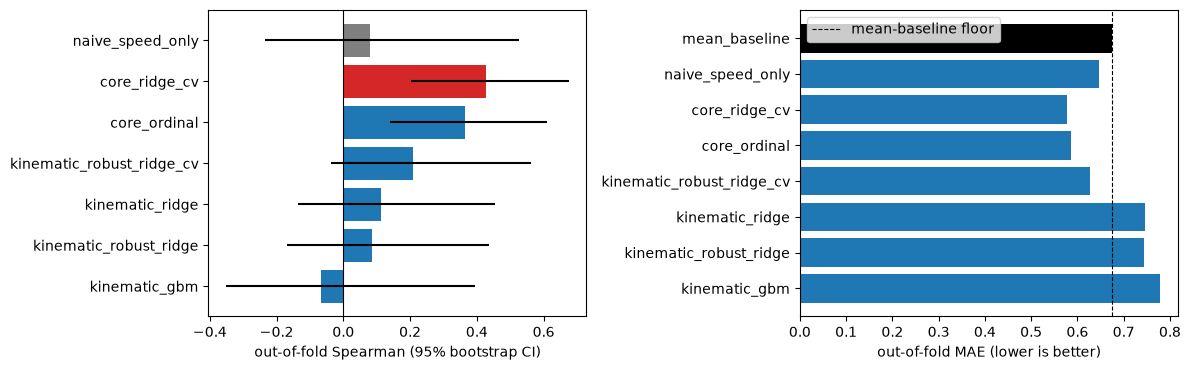

In [7]:
s = summary.set_index("arm").drop("mean_baseline")
lo = s["spearman"] - s["spearman_ci"].map(lambda c: c[0])
hi = s["spearman_ci"].map(lambda c: c[1]) - s["spearman"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
colors = ["tab:red" if a == PRIMARY_ARM else ("tab:gray" if a == BASELINE_ARM else "tab:blue")
          for a in s.index]
ax[0].barh(s.index, s["spearman"], xerr=[lo, hi], color=colors)
ax[0].axvline(0, c="k", lw=.8); ax[0].set_xlabel("out-of-fold Spearman (95% bootstrap CI)")
ax[0].invert_yaxis()
mae = summary.set_index("arm")["mae"]
ax[1].barh(mae.index, mae, color=["k" if a == "mean_baseline" else "tab:blue" for a in mae.index])
ax[1].axvline(mae["mean_baseline"], c="k", ls="--", lw=.8, label="mean-baseline floor")
ax[1].set_xlabel("out-of-fold MAE (lower is better)"); ax[1].invert_yaxis(); ax[1].legend()
plt.tight_layout()

In [8]:
p = summary.set_index("arm").loc[PRIMARY_ARM]
print(f"PRIMARY ({PRIMARY_ARM}) vs {BASELINE_ARM}: "
      f"Δρ = {p['delta_spearman']:+.3f}, 95% CI [{p['delta_ci'][0]:+.3f}, {p['delta_ci'][1]:+.3f}], "
      f"one-sided p = {p['p_vs_naive']:.3f}")
print("Power reminder: n≈47 detects ρ=0.4, n≈30 detects ρ=0.5 (80%, α=.05). "
      "A Δρ of ~0.1–0.2 between two correlated arms needs far more clips.")

PRIMARY (core_ridge_cv) vs naive_speed_only: Δρ = +0.346, 95% CI [+0.010, +0.636], one-sided p = 0.020
Power reminder: n≈47 detects ρ=0.4, n≈30 detects ρ=0.5 (80%, α=.05). A Δρ of ~0.1–0.2 between two correlated arms needs far more clips.


**Reading.** On the 3-rater mean the primary arm reaches ρ = 0.43 and beats the speed-only baseline
(Δρ = +0.35, 95% CI [+0.01, +0.64], one-sided p = .02), with MAE below the mean-baseline floor.
**Pre-registered rule: this is not claimed as a result** because ICC(2,k) = 0.20 < 0.6 — a mean of raters who
disagree is not a reliable ground truth. It is reported as exploratory; the per-rater results below are the finding.

## 5b. Per-rater results (pre-registered low-agreement fallback)

Same primary arm and baseline, same signer-disjoint CV, evaluated against each rater alone.

In [9]:
per = []
arms = [{"name": BASELINE_ARM, "kind": "naive_speed", "feature_set": "naive"},
        {"name": PRIMARY_ARM, "kind": "ridge_cv", "feature_set": "core"},
        {"name": "core_ordinal", "kind": "ordinal", "feature_set": "core"}]
for rid, g in ratings.groupby("rater_id"):
    yr = consensus_scores(g)
    fr = feats_all[feats_all["clip_id"].isin(yr.index)].reset_index(drop=True)
    sm, _ = run_ablation(fr, yr, arms=arms, group_col="signer_id", n_splits=5, bootstrap_iters=1000)
    for row in sm.to_dict("records"):
        per.append({"rater": rid, "arm": row["arm"], "spearman": row["spearman"],
                    "ci": f"[{row['spearman_ci'][0]:+.2f}, {row['spearman_ci'][1]:+.2f}]",
                    "mae": row["mae"], "delta_vs_speed": row["delta_spearman"],
                    "p": row["p_vs_naive"]})
pd.DataFrame(per).set_index(["rater", "arm"])

spearman              ci    mae  delta_vs_speed      p
rater        arm                                                                     
fluent_c     naive_speed_only     0.060  [-0.27, +0.46]  0.647           0.000    NaN
             core_ridge_cv        0.187  [-0.12, +0.49]  0.663           0.127  0.218
             core_ordinal         0.260  [-0.05, +0.51]  0.661           0.200  0.204
instructor_a naive_speed_only     0.152  [-0.14, +0.54]  0.982           0.000    NaN
             core_ridge_cv        0.488  [+0.23, +0.75]  0.867           0.335  0.033
             core_ordinal         0.573  [+0.34, +0.79]  0.800           0.420  0.014
instructor_b naive_speed_only    -0.264  [-0.59, +0.18]  0.812           0.000    NaN
             core_ridge_cv       -0.370  [-0.65, +0.05]  0.804          -0.106  0.921
             core_ordinal        -0.124  [-0.37, +0.21]  0.840           0.140  0.187

**Reading.** The hypothesis holds for 2 of 3 raters in direction and for one at α = .05:
* `instructor_a` (Maya): primary ρ = 0.49 vs. speed-only 0.15 — Δρ = +0.34, p = .03; ordinal ρ = 0.57, p = .01.
* `fluent_c`: primary ρ = 0.19 vs. 0.06 — Δρ = +0.13, p = .22 (directionally consistent, n.s.).
* `instructor_b`: primary ρ = −0.37 vs. −0.26 — no support; this rater's scores are nearly unrelated to the
  kinematic features (§3).

Conclusion for the paper: kinematic features — smoothness above all — track fluency as judged by two of three
raters better than speed does, but humans do not agree well enough on 1–5 fluency of in-the-wild clips for a
reliable consensus test at n = 50. Rater reliability, not the pipeline, is the binding constraint.

## 6. Fairness (proposal §7)

`asl-fluency clip-context` derived objective strata for every rated clip, so no human annotation is needed:
* **skin_tone** — Individual Typology Angle (ITA°) from palm pixels located by the landmarks
  (light > 41°, medium 10–41°, dark ≤ 10°; Chardon et al. 1991 bands collapsed to 3).
* **lighting** — mean CIELAB L* of the frame, tertiles of the rated set.

ITA from compressed web video is confounded with white balance/exposure — it is a **proxy stratifier**
(the same pixels the tracker sees), not a demographic label.

In [10]:
ctx = pd.read_csv(resolve_path(cfg, "ratings_dir") / "clip_context.csv", dtype={"clip_id": str})
print(pd.crosstab(ctx["skin_tone"].fillna("undefined"), ctx["lighting"], margins=True), "\n")
print("ITA vs luma Spearman (confound check):",
      round(stats.spearmanr(ctx["ita_deg"], ctx["luma_L"], nan_policy="omit").statistic, 2))

lighting   bright  low  normal  All
skin_tone                          
dark            5    3       4   12
light           3    4       4   11
medium          6    9       8   23
undefined       3    1       0    4
All            17   17      16   50 

ITA vs luma Spearman (confound check): -0.22


**Tracker-quality gap.** §7's bias mechanism is *dropped/jittery tracking* for some groups, which would
corrupt kinematic features independent of skill. Check detection rate per stratum (and whether
ratings themselves differ by stratum, which would confound the stratified metrics).

In [11]:
q = ctx.merge(feats[["clip_id", "detection_rate"]], on="clip_id").merge(
    y.rename("rating"), left_on="clip_id", right_index=True)
rows = []
for f in ("skin_tone", "lighting"):
    g = q.groupby(q[f].fillna("undefined"))
    rows.append(g.agg(n=("clip_id", "size"), detection_rate=("detection_rate", "mean"),
                      mean_rating=("rating", "mean")).assign(factor=f))
    groups = [x["detection_rate"].dropna() for _, x in q.dropna(subset=[f]).groupby(f)]
    print(f"{f}: Kruskal-Wallis on detection_rate p = {stats.kruskal(*groups).pvalue:.3f}")
pd.concat(rows).reset_index(names="stratum").set_index(["factor", "stratum"])

skin_tone: Kruskal-Wallis on detection_rate p = 0.184
lighting: Kruskal-Wallis on detection_rate p = 0.994


n  detection_rate  mean_rating
factor    stratum                                   
skin_tone dark       12           0.984        2.972
          light      11           0.998        3.061
          medium     23           0.996        3.246
          undefined   4           0.977        2.250
lighting  bright     17           0.994        2.863
          low        17           0.991        3.039
          normal     16           0.991        3.292

In [12]:
oof = details[PRIMARY_ARM]["oof"]
marginal_stratified_metrics(y, oof, ctx, ["skin_tone", "lighting"])

,factor,stratum,spearman,pearson,mae,n,mean_signed_error
0,skin_tone,dark,0.555,0.459,0.602,12.0,-0.010
1,skin_tone,light,0.373,0.411,0.590,11.0,0.057
2,skin_tone,medium,0.263,0.281,0.541,23.0,-0.164
3,skin_tone,NaN,-0.211,-0.451,0.692,4.0,0.692
4,lighting,bright,0.632,0.478,0.614,17.0,0.193
5,lighting,low,0.362,0.387,0.537,17.0,0.009
6,lighting,normal,0.172,0.227,0.584,16.0,-0.246


Strata hold 11–23 clips, so per-stratum correlations have very wide CIs — report them descriptively and
lean on **mean signed error** (systematic over/under-scoring), which is the bias §7 is worried about.
Computed on the 3-rater mean (exploratory, like §5).

Reading:
* **No tracker-quality gap**: detection rate is ≥ 0.98 in every stratum (Kruskal–Wallis n.s.), so the
  §7 mechanism (dropped frames for some groups) is not visible in the rated set.
* Skin-tone signed errors are small (|bias| ≤ 0.17). Lighting errors range −0.25 (normal) to +0.19
  (bright); with 16–17 clips per stratum and low rater agreement, treat these as noise-level.
* The `NaN`/undefined ITA rows are clips where palm pixels had b* ≤ 0 (strong colour cast) — itself a
  capture-quality signal; n = 4, so not interpretable on its own. To scale this up cheaply: `asl-fluency clip-context --all --out data/processed/clip_context_all.csv`
gives detection-rate-by-stratum over the whole 7k-clip corpus (no ratings needed).

## 7. Boundary-sensitivity recap (Roadmap Gap 1)

In [13]:
bs = pd.read_csv(resolve_path(cfg, "processed_dir") / "boundary_sensitivity.csv")
bs.assign(in_core=bs["feature"].isin(CORE_FEATURES)).sort_values("min_rho")

,feature,rho_jit2,rho_jit4,rho_jit6,min_rho,in_core
0,letter_dur_std_s,0.136,-0.006,-0.016,-0.016,False
1,letter_dur_cv,0.625,0.481,0.542,0.481,False
2,trans_vel_std,0.912,0.723,0.714,0.714,False
3,trans_vel_mean,0.949,0.754,0.763,0.754,False
4,trans_acc_std,0.938,0.819,0.816,0.816,False
5,trans_jerk_std,0.945,0.843,0.859,0.843,False
6,trans_acc_mean,0.965,0.846,0.848,0.846,False
7,trans_jerk_mean,0.974,0.878,0.893,0.878,False
8,trans_jerk_max,0.972,0.881,0.898,0.881,False
9,letter_dur_mean_s,1.000,0.999,0.998,0.998,False


All three **core** features are whole-clip quantities (rate, LDJ, pause time) and are robust to
boundary jitter, so the primary test does not depend on a better aligner. That justifies deferring the
CTC aligner; the remaining Gap 1 item is human: `asl-fluency label-boundaries` on these same 50 clips to
report actual boundary error in the paper.

## 8. Dress rehearsal on simulated raters (historical plumbing check)

Kept for the record: before the instructor ratings existed, two simulated raters (`fluent_c` + noise)
verified the 3-rater path end-to-end. **Superseded by the real ratings above** — these numbers are not results
and are never written to disk.

In [14]:
rng = np.random.default_rng(0)
base = ratings[ratings["rater_id"] == "fluent_c"][["clip_id", "rating"]]
sims = [base.assign(rater_id=f"sim_{k}",
                    rating=np.clip(np.rint(base["rating"] + rng.normal(0, sd, len(base))), 1, 5))
        for k, sd in (("a", 0.6), ("b", 0.9))]
sim = pd.concat([base.assign(rater_id="fluent_c"), *sims], ignore_index=True)
print({k: round(v, 3) for k, v in agreement_report(sim).items()})
y_sim = consensus_scores(sim)
sim_summary, _ = run_ablation(feats, y_sim, group_col="signer_id", n_splits=5, bootstrap_iters=200)
sim_summary[["arm", "spearman", "mae", "delta_spearman", "p_vs_naive"]]

{'n_clips': 50.0, 'n_raters': 3.0, 'fleiss_kappa': 0.226, 'icc_2k': 0.591}


,arm,spearman,mae,delta_spearman,p_vs_naive
0,mean_baseline,NaN,0.668,NaN,NaN
1,naive_speed_only,0.069,0.646,0.000,NaN
2,core_ridge_cv,0.317,0.622,0.248,0.050
3,core_ordinal,0.346,0.617,0.276,0.080
4,kinematic_robust_ridge_cv,0.306,0.628,0.236,0.105
5,kinematic_ridge,0.241,0.715,0.172,0.270
6,kinematic_robust_ridge,0.255,0.699,0.185,0.255
7,kinematic_gbm,0.170,0.671,0.100,0.325


## 9. Commands used to produce these results

```bash
asl-fluency agreement data/ratings/ratings_intake.csv                        # ICC(2,k) = 0.20 < 0.6
asl-fluency evaluate  data/ratings/ratings_intake.csv                        # 3-rater mean (exploratory)
asl-fluency evaluate  data/ratings/ratings_intake.csv --rater fluent_c       # per-rater (reported)
asl-fluency evaluate  data/ratings/ratings_intake.csv --rater instructor_a
asl-fluency evaluate  data/ratings/ratings_intake.csv --rater instructor_b
asl-fluency train && asl-fluency score --from-features
asl-fluency site --out _site                                                 # webpage (CI does this)
```
Optional, only if time allows: a second rating batch (`asl-fluency rating-sheet … --batch 2`) with a rater
calibration step first (shared anchor clips for 1/3/5) to raise agreement.

## 10. Notes & limitations (for the paper)

* **Low rater agreement.** ICC(2,k) = 0.20, Fleiss' κ = −0.05: raters differ in scale use (means 2.2–3.9)
  and only moderately in ranking (ρ ≈ 0.35–0.40). No consensus claim is made (pre-registered rule).
* **Hypothesis: mixed, per rater.** Supported at α = .05 for 1 of 3 raters, directionally for 2 of 3.
* **Restricted range.** Corpus is mostly fluent signers, capping correlations.
* **Small n.** 50 clips / 27 signers; signer-disjoint 5-fold CV ⇒ ~40 training clips per fold. This is why
  the model is 3 a-priori features with shrinkage, not 18 features or a deep model (§7).
* **Uniform segmentation.** Core features are whole-clip and boundary-robust; `trans_*` features are not
  in the primary arm.
* **Fairness proxy.** ITA on web video ≠ skin tone; it's confounded with capture conditions. Strata are small.
* **Frame rate.** Frame directories have no native fps; 30 fps assumed for all rate features.